# Seminar 3 — Supplementary study: feature generation with language models

### Learning objectives

1. Discover and review a feature schema from unlabelled text.
2. Generate structured feature values and inspect missing outputs.
3. Compare a classifier using generated features with a text baseline.
4. Distinguish live model output from recorded or synthetic replay data.

### Method and dataset

The `llm-feature-gen` package supports schema discovery and feature generation.
The example trains a shallow decision tree on generated categorical attributes.

| Property | Value |
|---|---|
| Source | Banking77, `mteb/banking77`, MIT licence |
| Classes | `card_arrival` and `card_delivery_estimate` |
| Sample | 48 customer messages |
| Split per class | 16 training messages and 8 test messages |

### LiteLLM access

All live calls use the school LiteLLM proxy. The setup cell contains the course
key shared by all students of the course; do not pass it on outside the course.
`LLM_API_KEY` in the kernel environment overrides it.
The default chat model is `qwen3.6-35b`; `LLM_CHAT_MODEL` can override it.
The `LocalProvider` adapter sends requests to LiteLLM's compatible API.

### Execution modes

| Mode | Behaviour |
|---|---|
| Online | Obtains responses from the configured endpoint. |
| Online with recording | `LFG_RECORD=1` saves responses to `replay.json`. |
| Replay | Loads responses from `replay.json` without contacting an endpoint. |

**Data provenance:** the supplied replay file contains synthetic, keyword-based outputs. It verifies the workflow and does not measure live language-model quality. Recording an online run replaces it with model responses.

### Contents

1. Data layout
2. Provider interfaces
3. Schema discovery
4. Feature generation
5. Classifier comparison and caching
6. Review

### Package references

- Package: <https://pypi.org/project/llm-feature-gen/>
- Source and documentation: <https://github.com/JuliaYershova/llm-feature-gen>

In [1]:
#%pip install llm-feature-gen

In [2]:
import os, json, hashlib, shutil
from pathlib import Path
import pandas as pd

try:
    import llm_feature_gen
    from llm_feature_gen import discover_features_from_texts, generate_features_from_texts
    from llm_feature_gen.providers import LocalProvider
except ImportError as e:
    raise ImportError("llm-feature-gen is not installed: run   pip install --user llm-feature-gen   and restart the kernel") from e

BASE_URL   = "https://litellm.vse.cz/v1/"
CHAT_MODEL = os.environ.get("LLM_CHAT_MODEL", "qwen3.6-35b")
API_KEY    = os.environ.get("LLM_API_KEY", "sk-8zOh3SmFx54QQfihNoXm5w").strip()   # shared course key

DATA   = Path(os.environ.get("LFG_DATA", "llm_feature_gen_data"))   # sample + replay fixture
RECORD = os.environ.get("LFG_RECORD") == "1"
WORK, OUT = Path("work"), Path("outputs")

print("llm-feature-gen", getattr(llm_feature_gen, "__version__", "?"), "| data folder:", DATA.resolve())

llm-feature-gen 0.1.13 | data folder: /srv/exchange/4iz566-582_ZS2627/llm_feature_gen_data


## 1 Data preparation

### 1.1 Dataset and directory layout

The following cell loads the sample and prepares the directories used by the package.

In [3]:
CLASSES = ["card_arrival", "card_delivery_estimate"]
df = pd.read_csv(DATA / "banking77_sample.csv")
print(df.groupby(["split", "label"]).size())
df.sample(5, random_state=0)

split  label                 
test   card_arrival               8
       card_delivery_estimate     8
train  card_arrival              16
       card_delivery_estimate    16
dtype: int64


,text,label,split
29,When shipped to the US how long is delivery time?,card_delivery_estimate,train
4,"I was supposed to receive my new card by now, ...",card_arrival,train
26,When should I expect my card to arrive?,card_delivery_estimate,train
30,How long is the delivery to the US?,card_delivery_estimate,train
32,I have been waiting longer than expected for m...,card_arrival,test


### 1.2 Discovery and generation inputs

| Stage | Input layout | Role of labels |
|---|---|---|
| Discovery | A folder containing a small sample of unlabelled training texts | Labels are excluded from schema discovery. |
| Generation | One subfolder per class | Labels organise files for evaluation; they must not be included in feature-generation prompts. |

Schema discovery identifies variation in the text. Feature relevance and interpretability require subsequent review.

In [4]:
for d in (WORK, OUT):
    shutil.rmtree(d, ignore_errors=True)
discover_dir = WORK / "discover"; discover_dir.mkdir(parents=True)
for cls in CLASSES:
    (WORK / "train" / cls).mkdir(parents=True); (WORK / "test" / cls).mkdir(parents=True)

n_discover = 0
for split in ("train", "test"):
    for cls in CLASSES:
        part = df[(df["split"] == split) & (df["label"] == cls)].reset_index(drop=True)
        for i, text in enumerate(part["text"]):
            (WORK / split / cls / f"{cls}_{i:02d}.txt").write_text(text, encoding="utf-8")
            if split == "train" and i < 4:
                (discover_dir / f"{cls}_{i:02d}.txt").write_text(text, encoding="utf-8"); n_discover += 1
print("discovery sample:", n_discover, "texts (4 per class, labels not shown to the model)")
print("train files:", sum(1 for _ in (WORK / "train").rglob("*.txt")), "| test files:", sum(1 for _ in (WORK / "test").rglob("*.txt")))

discovery sample: 8 texts (4 per class, labels not shown to the model)
train files: 32 | test files: 16


## 2 Provider interfaces

- `LocalProvider` connects the library to a compatible model endpoint.
- `text_features(list_of_texts, prompt=...)` returns one feature dictionary per input text.
- A replay provider implements the same interface using stored responses.

Keeping the interface consistent supports offline execution and separates model access from downstream analysis.

In [5]:
def _key(text):
    return hashlib.sha256(text.strip().encode("utf-8")).hexdigest()[:16]

def _is_discovery_call(text, prompt):
    # the joint discovery call sends every sample text in ONE request, joined by a separator
    return "proposed_features" in (prompt or "") and "\n\n---\n\n" in text


class ReplayProvider:
    """Answers from replay.json. Same one-method interface the library calls on a real provider."""
    text_model, base_url, temperature, max_tokens, supports_response_schema = "replay", "replay://", 0.0, 2048, False

    def __init__(self, fixture):
        self.fx, self.misses = fixture, 0

    def text_features(self, text_list, prompt=None, deployment_name=None, feature_gen=False, **_):
        out = []
        for text in text_list:
            if _is_discovery_call(text, prompt):
                out.append(self.fx["_discovery"]); continue
            hit = self.fx.get(_key(text))
            if hit is None:                                  # text not in the recording
                self.misses += 1
                hit = {f["feature"]: "not given by LLM" for f in self.fx["_discovery"]["proposed_features"]}
            out.append(hit)
        return out


class RecordingProvider:
    """Wraps the real provider and records every answer under the keys ReplayProvider uses."""
    def __init__(self, inner):
        self.inner = inner
        self.fx = {"_meta": {"synthetic": False, "model": CHAT_MODEL, "base_url": BASE_URL}}

    def __getattr__(self, name):                             # everything else goes to the real provider
        return getattr(self.inner, name)

    def text_features(self, text_list, prompt=None, **kw):
        res = self.inner.text_features(text_list, prompt=prompt, **kw)
        for text, r in zip(text_list, res):
            if _is_discovery_call(text, prompt): self.fx["_discovery"] = r
            else: self.fx[_key(text)] = r
        return res


def probe():
    fixture = json.load(open(DATA / "replay.json", encoding="utf-8"))
    if not API_KEY:
        print("LLM_API_KEY is empty — replay mode"); return ReplayProvider(fixture), "replay"
    try:
        from openai import OpenAI
        OpenAI(base_url=BASE_URL, api_key=API_KEY, timeout=10.0, max_retries=0).models.list()
    except Exception as e:
        status = getattr(e, "status_code", None)
        if status in (401, 403): print(f"AUTHENTICATION FAILED ({status}) — the course key was rejected; replay mode meanwhile")
        else: print(f"endpoint unreachable ({type(e).__name__}) — replay mode")
        return ReplayProvider(fixture), "replay"
    real = LocalProvider(base_url=BASE_URL, api_key=API_KEY, default_text_model=CHAT_MODEL, temperature=0.0)
    return (RecordingProvider(real), "online+record") if RECORD else (real, "online")

provider, MODE = probe()
meta = json.load(open(DATA / "replay.json", encoding="utf-8")).get("_meta", {})
print("MODE =", MODE, "| replay fixture is synthetic:", meta.get("synthetic"))

MODE = online | replay fixture is synthetic: True


## 3 Schema discovery

### 3.1 Discovery request

The example submits eight sample texts and requests a compact feature schema.
Each proposed feature includes:

1. A name.
2. A rationale.
3. A set of allowed values.

A small schema facilitates inspection of feature definitions and the resulting classifier.

In [6]:
discovered = discover_features_from_texts(
    texts_or_file=str(discover_dir), provider=provider, as_set=True, min_features=4,
    output_dir=str(OUT), output_filename="discovered_text_features.json")
schema = discovered if isinstance(discovered, dict) else discovered[0]
FEATURES = [f["feature"] for f in schema["proposed_features"]]
for f in schema["proposed_features"]:
    print(f"- {f['feature']}: {f['description'][:90]}")
    print(f"      values: {f['possible_values']}")

Features saved to outputs/discovered_text_features.json
- temporal_reference_type: Distinguishes between texts that anchor the inquiry in a specific past event or duration (
      values: ['Specific past duration/event', 'General future expectation', 'Immediate present state', 'Conditional future scenario']
- inquiry_focus: Identifies whether the primary intent is to track the status of an existing order (deliver
      values: ['Status tracking (when/where)', 'Logistics modification (choice/date)', 'Existence confirmation (have I got it)', 'General policy inquiry']
- grammatical_formality: Captures the level of syntactic structure and orthographic correctness. Some texts use sta
      values: ['Formal/Standard grammar', 'Informal/Lowercase only', 'Abbreviated/Slang', 'Mixed case with errors']
- entity_specificity: Determines if the text refers to a generic object ('card') or introduces specific contextu
      values: ['Generic entity reference', 'Specific geographic constraint', 'Speci

### 3.2 Schema review

| Criterion | Review question |
|---|---|
| Observability | Can the value be inferred from the text alone? |
| Category definition | Are allowed values sufficiently distinct and well defined? |
| Relevance | Could the feature help distinguish the intended classes? |
| Interpretability | Can a reviewer explain the feature and its role in a decision? |

Schema validity and readable decision rules do not by themselves establish predictive usefulness.

## 4 Feature generation

### 4.1 Generated data

The example generates features for 48 texts and writes class-specific CSV files.
With `merge_to_single_csv=True`, it also creates a combined file.

| Column | Content |
|---|---|
| `File` | Source text identifier |
| `Class` | Reference class |
| Feature columns | Generated categorical values |
| `raw_llm_output` | Response retained for inspection |

The string `not given by LLM` marks an unsupplied feature value. Count these values and inspect their distribution before modelling.

In [7]:
paths = {}
for split in ("train", "test"):
    paths[split] = generate_features_from_texts(
        root_folder=str(WORK / split), discovered_features_path=str(OUT / "discovered_text_features.json"),
        provider=provider, classes=CLASSES, output_dir=str(OUT / split),
        merge_to_single_csv=True, merged_csv_name=f"{split}_feature_values.csv")

train = pd.read_csv(paths["train"]["__merged__"]); test = pd.read_csv(paths["test"]["__merged__"])
missing = int((train[FEATURES] == "not given by LLM").sum().sum() + (test[FEATURES] == "not given by LLM").sum().sum())
print("rows:", train.shape, test.shape, "| values not given by the model:", missing,
      "| replay misses:", getattr(provider, "misses", 0))
train.drop(columns=["raw_llm_output"]).head()

card_delivery_estimate: 100%|██████████| 8/8 [00:06<00:00,  1.29file/s]

rows: (32, 7) (16, 7) | values not given by the model: 0 | replay misses: 0


,File,Class,temporal_reference_type,inquiry_focus,grammatical_formality,entity_specificity
0,card_arrival_00.txt,card_arrival,Specific past duration/event,Status tracking (when/where),Formal/Standard grammar,Generic entity reference
1,card_arrival_01.txt,card_arrival,General future expectation,Status tracking (when/where),Formal/Standard grammar,Generic entity reference
2,card_arrival_02.txt,card_arrival,Immediate present state,Existence confirmation (have I got it),Informal/Lowercase only,Generic entity reference
3,card_arrival_03.txt,card_arrival,General future expectation,Status tracking (when/where),Formal/Standard grammar,Generic entity reference
4,card_arrival_04.txt,card_arrival,Specific past duration/event,Status tracking (when/where),Mixed case with errors,Generic entity reference


## 5 Classifier comparison

### 5.1 Models and evaluation

| Model | Representation |
|---|---|
| Depth-limited decision tree | One-hot encoded generated features |
| Logistic regression baseline | TF-IDF features from the original text |

The tree uses maximum depth 3 to retain readable decision rules.
Both models use the same split. With only 16 training examples per class, results are illustrative and should not be interpreted as a stable estimate of comparative performance.

In [8]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

X_train = pd.get_dummies(train[FEATURES].astype(str), dtype=int)
X_test = pd.get_dummies(test[FEATURES].astype(str), dtype=int)
X_train, X_test = X_train.align(X_test, join="outer", axis=1, fill_value=0)
y_train, y_test = train["Class"], test["Class"]

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
tr, te = df[df["split"] == "train"], df[df["split"] == "test"]
baseline = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000)).fit(tr["text"], tr["label"])

pred_tree, pred_base = tree.predict(X_test), baseline.predict(te["text"])
results = pd.DataFrame({
    "accuracy": [accuracy_score(y_test, pred_tree), accuracy_score(te["label"], pred_base)],
    "macro F1": [f1_score(y_test, pred_tree, average="macro"), f1_score(te["label"], pred_base, average="macro")],
}, index=["decision tree on LLM features", "TF-IDF + logistic regression"]).round(3)
print("(replay mode with the synthetic fixture: the tree's numbers reflect keyword rules, not a model)" if MODE == "replay" else "")
results

,accuracy,macro F1
decision tree on LLM features,0.812,0.806
TF-IDF + logistic regression,0.812,0.812


|--- grammatical_formality_Formal/Standard grammar <= 0.50
|   |--- class: card_arrival
|--- grammatical_formality_Formal/Standard grammar >  0.50
|   |--- temporal_reference_type_General future expectation <= 0.50
|   |   |--- inquiry_focus_Logistics modification (choice/date) <= 0.50
|   |   |   |--- class: card_arrival
|   |   |--- inquiry_focus_Logistics modification (choice/date) >  0.50
|   |   |   |--- class: card_delivery_estimate
|   |--- temporal_reference_type_General future expectation >  0.50
|   |   |--- entity_specificity_Generic entity reference <= 0.50
|   |   |   |--- class: card_delivery_estimate
|   |   |--- entity_specificity_Generic entity reference >  0.50
|   |   |   |--- class: card_delivery_estimate



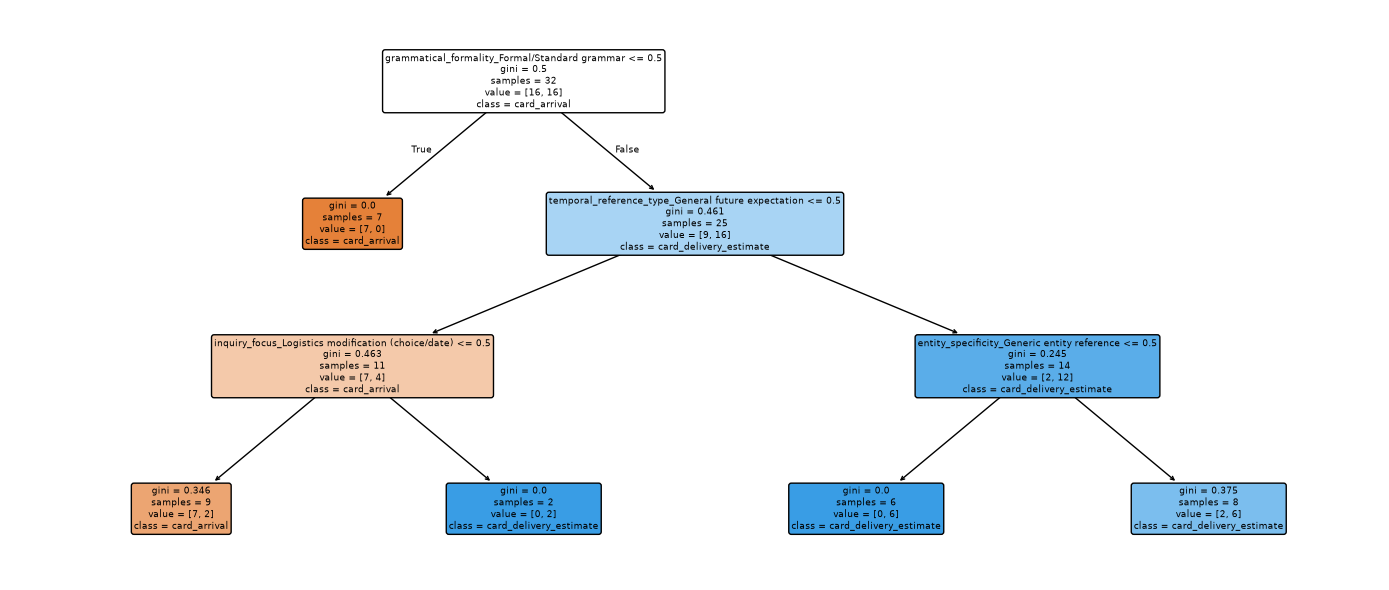

In [9]:
print(export_text(tree, feature_names=list(X_train.columns)))
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree, feature_names=list(X_train.columns), class_names=sorted(y_train.unique()), filled=True, rounded=True, ax=ax)
fig.tight_layout()

### 5.2 Interpretation and computational cost

- Generated features can express decision rules using explicit text attributes.
- Feature quality depends on the schema and the correctness of model outputs.
- Live generation introduces request costs and possible variation between runs, including at temperature 0.
- Retaining the schema and generated values supports reproducibility and inspection.

### 5.3 Batching and caching

`llm_feature_gen.batch.generate_features_from_texts_cached` supports batches and a disk cache keyed by text and schema.
Cached results reduce repeated requests; new inputs or changed schemas may require additional generation.
The following example applies to online execution.

In [10]:
if MODE.startswith("online"):
    try:
        from llm_feature_gen.batch import generate_features_from_texts_cached
        cached = generate_features_from_texts_cached(
            root_folder=str(WORK / "test"), discovered_features_path=str(OUT / "discovered_text_features.json"),
            provider=provider, classes=CLASSES, output_dir=str(OUT / "test_cached"),
            merge_to_single_csv=True, batch_size=8, cache_file=str(OUT / "feature_cache.json"))
        print("cached run written to", cached.get("__merged__"))
    except Exception as e:
        print("batched/cached variant not available in this version:", type(e).__name__, str(e)[:120])
else:
    print("online only — skipped in", MODE, "mode")

Batch generation: 100%|██████████| 1/1 [00:06<00:00,  6.14s/batch]


Saved batch results to outputs/test_cached/card_arrival_feature_values.csv


Batch generation: 100%|██████████| 1/1 [00:06<00:00,  6.13s/batch]

Saved batch results to outputs/test_cached/card_delivery_estimate_feature_values.csv
cached run written to outputs/test_cached/all_feature_values.csv


## 6 Review

### Reproducible analysis sequence

1. Define a text dataset and classification target, then establish the evaluation split.
2. Discover a schema using a training-only sample with target labels excluded.
3. Review feature definitions and allowed values; fix the schema before test evaluation.
4. Generate features for training and test texts without exposing target labels to the model.
5. Compare a classifier on the generated features with a TF-IDF baseline under the same evaluation protocol.
6. Retain the schema, generated data, model configuration and comparison results for reproducibility.

### Review questions

1. How can schema discovery introduce information leakage?
2. What distinguishes a replay demonstration from evaluation of a live model?
3. Why should missing generated values be inspected before fitting the classifier?
4. Which aspects of interpretability and predictive performance should be evaluated separately?

In [11]:
if RECORD and MODE == "online+record":
    DATA.mkdir(parents=True, exist_ok=True)
    json.dump(provider.fx, open(DATA / "replay.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
    print("recorded", len(provider.fx) - 2, "texts + schema ->", (DATA / "replay.json").resolve())
    print("copy it to tools/materials_build/fixtures/llm_feature_gen/replay.json and re-publish")
usage = getattr(provider, "usage_summary", None)
print(usage() if callable(usage) else f"usage accounting: not available from the {MODE} provider")

usage accounting: not available from the online provider
